# Bank Marketing | Exploratory Data Analysis
**Project 01 — ML Portfolio**  
**Dataset:** UCI Bank Marketing (`bank-full.csv`) · **Objective:** Identify patterns associated with term-deposit subscriptions.

This notebook explores data quality, distributions, outliers, and subscription patterns. Results are **descriptive associations**, not evidence of causation. No predictive model is trained here.

**Run instructions:** On Kaggle, attach the Bank Marketing dataset; otherwise place `bank-full.csv` in `data/` beside this notebook. Run all cells in order. [Dataset documentation](https://archive.ics.uci.edu/dataset/222/bank+marketing).

## 1 · Setup and data overview

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

plt.rcParams.update({
    "figure.figsize": (9, 4.8),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "semibold",
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "font.size": 10,
    "grid.alpha": 0.18,
    "savefig.bbox": "tight",
})
BLUE = "#2563A6"
TEAL = "#168A82"
ORANGE = "#DE8742"
PALE = "#B5D7E7"

paths = [
    Path("/kaggle/input/datasets/nightfury22344/bank-marketing-eda/bank/bank-full.csv"),
    Path("/kaggle/input/bank-marketing-eda/bank/bank-full.csv"),
    Path("data/bank-full.csv"),
    Path("bank-full.csv"),
]
source = next((p for p in paths if p.is_file()), None)
if source is None and Path("/kaggle/input").exists():
    source = next(Path("/kaggle/input").rglob("bank-full.csv"), None)
if source is None:
    raise FileNotFoundError("Attach the Bank Marketing dataset on Kaggle or place bank-full.csv in data/.")

df = pd.read_csv(source, sep=";")
print(f"Loaded {len(df):,} rows × {df.shape[1]} columns from {source}")
display(df.head())

Loaded 45,211 rows × 17 columns from /kaggle/input/datasets/nightfury22344/bank-marketing-eda/bank/bank-full.csv


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [2]:
df.info()
display(df.describe().round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


,age,balance,day,duration,campaign,pdays,previous
count,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00
mean,40.94,1362.27,15.81,258.16,2.76,40.20,0.58
std,10.62,3044.77,8.32,257.53,3.10,100.13,2.30
min,18.00,-8019.00,1.00,0.00,1.00,-1.00,0.00
25%,33.00,72.00,8.00,103.00,1.00,-1.00,0.00
50%,39.00,448.00,16.00,180.00,2.00,-1.00,0.00
75%,48.00,1428.00,21.00,319.00,3.00,-1.00,0.00
max,95.00,102127.00,31.00,4918.00,63.00,871.00,275.00


## 2 · Data quality and special values
`unknown` is a recorded category, not a pandas null. The value `pdays = -1` means no previous contact. Both require context before cleaning.

In [3]:
unknown_cols = ["job", "education", "contact", "poutcome"]
quality = pd.DataFrame({
    "unknown_count": [(df[col] == "unknown").sum() for col in unknown_cols],
    "unknown_pct": [100 * (df[col] == "unknown").mean() for col in unknown_cols],
}, index=unknown_cols)
print("Null entries:", int(df.isna().sum().sum()))
display(quality.round(2))
display(pd.crosstab(df["previous"].eq(0), df["poutcome"], rownames=["No previous contacts"]))

Null entries: 0


,unknown_count,unknown_pct
job,288,0.64
education,1857,4.11
contact,13020,28.80
poutcome,36959,81.75


poutcome,failure,other,success,unknown
No previous contacts,,,,
False,4901,1840,1511,5
True,0,0,0,36954


## 3 · Numerical distributions and outliers
Extreme balances can compress the histogram. Comparing the full range with a focused view makes the distribution easier to read; the original records remain unchanged.

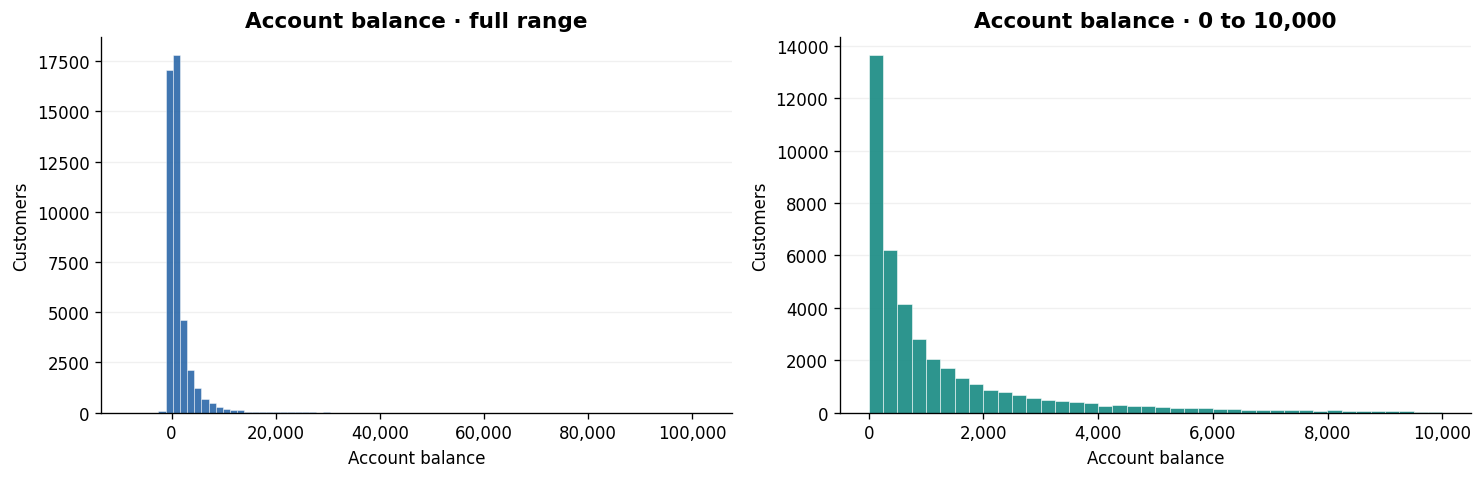

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.1))
axes[0].hist(df["balance"], bins=80, color=BLUE, alpha=0.88, edgecolor="white", linewidth=0.3)
axes[0].set(title="Account balance · full range", xlabel="Account balance", ylabel="Customers")
focus = df.loc[df["balance"].between(0, 10_000), "balance"]
axes[1].hist(focus, bins=40, color=TEAL, alpha=0.9, edgecolor="white", linewidth=0.35)
axes[1].set(title="Account balance · 0 to 10,000", xlabel="Account balance", ylabel="Customers")
for ax in axes:
    ax.grid(axis="y")
    ax.set_axisbelow(True)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}"))
plt.tight_layout()
plt.show()

,Value
Q1,72.0
Q3,1428.0
IQR,1356.0
Lower fence,-1962.0
Upper fence,3462.0
Lower outliers,17.0
Upper outliers,4712.0
Total flagged,4729.0


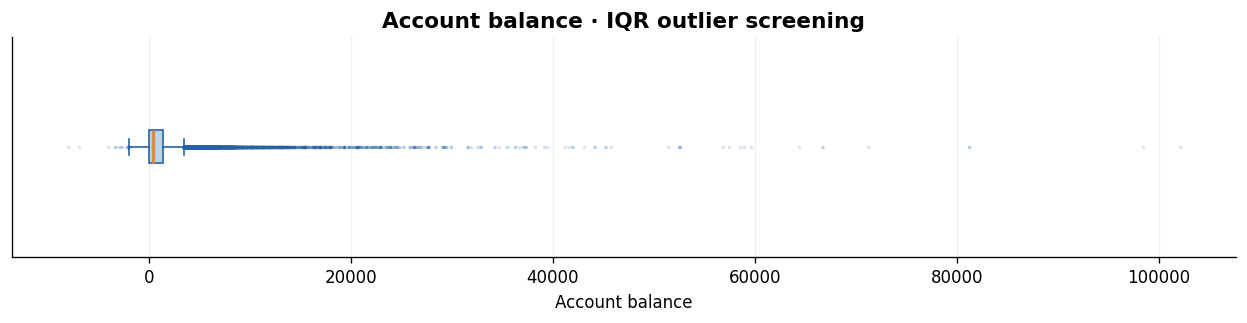

In [5]:
q1, q3 = df["balance"].quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
lower_outliers = int(df["balance"].lt(lower_fence).sum())
upper_outliers = int(df["balance"].gt(upper_fence).sum())
display(pd.DataFrame({
    "Q1": [q1], "Q3": [q3], "IQR": [iqr],
    "Lower fence": [lower_fence], "Upper fence": [upper_fence],
    "Lower outliers": [lower_outliers], "Upper outliers": [upper_outliers],
    "Total flagged": [lower_outliers + upper_outliers],
}).T.rename(columns={0: "Value"}))

fig, ax = plt.subplots(figsize=(10.5, 2.8))
ax.boxplot(df["balance"], vert=False, patch_artist=True,
           boxprops={"facecolor": PALE, "edgecolor": BLUE},
           medianprops={"color": ORANGE, "linewidth": 2},
           whiskerprops={"color": BLUE}, capprops={"color": BLUE},
           flierprops={"marker": ".", "markersize": 2, "alpha": 0.18, "markeredgecolor": BLUE})
ax.set(title="Account balance · IQR outlier screening", xlabel="Account balance", yticks=[])
ax.grid(axis="x")
plt.tight_layout()
plt.show()

**Interpretation:** The IQR rule flags potential outliers, not incorrect records. These observations are retained for the remaining analysis.

## 4 · Subscription outcomes

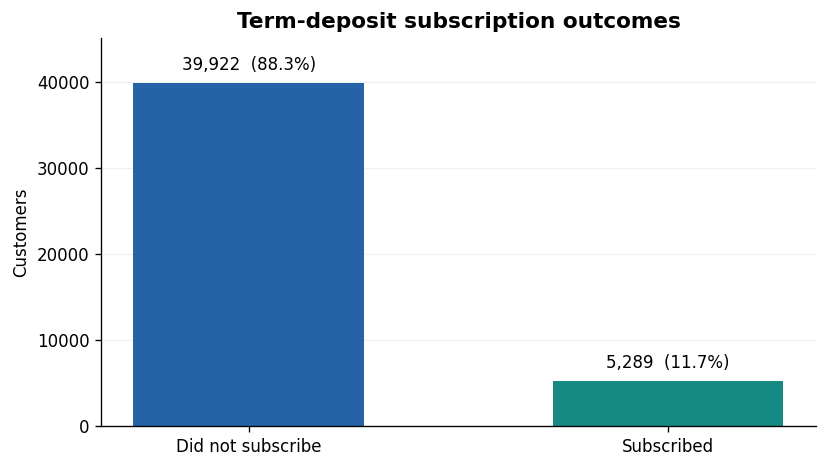

In [6]:
outcomes = df["y"].value_counts().reindex(["no", "yes"])
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["Did not subscribe", "Subscribed"], outcomes, color=[BLUE, TEAL], width=0.55)
for bar, value in zip(bars, outcomes):
    ax.annotate(f"{value:,}  ({value / len(df):.1%})", (bar.get_x() + bar.get_width()/2, value),
                ha="center", va="bottom", xytext=(0, 5), textcoords="offset points", fontsize=10)
ax.set(title="Term-deposit subscription outcomes", ylabel="Customers", ylim=(0, outcomes.max()*1.13))
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 5 · Occupation and subscription
Always compare **within-group rates** alongside subscription counts: groups differ greatly in size.

,customers,subscriptions,rate_pct
job,,,
student,938,269,28.68
retired,2264,516,22.79
unemployed,1303,202,15.50
management,9458,1301,13.76
admin.,5171,631,12.20
self-employed,1579,187,11.84
unknown,288,34,11.81
technician,7597,840,11.06
services,4154,369,8.88


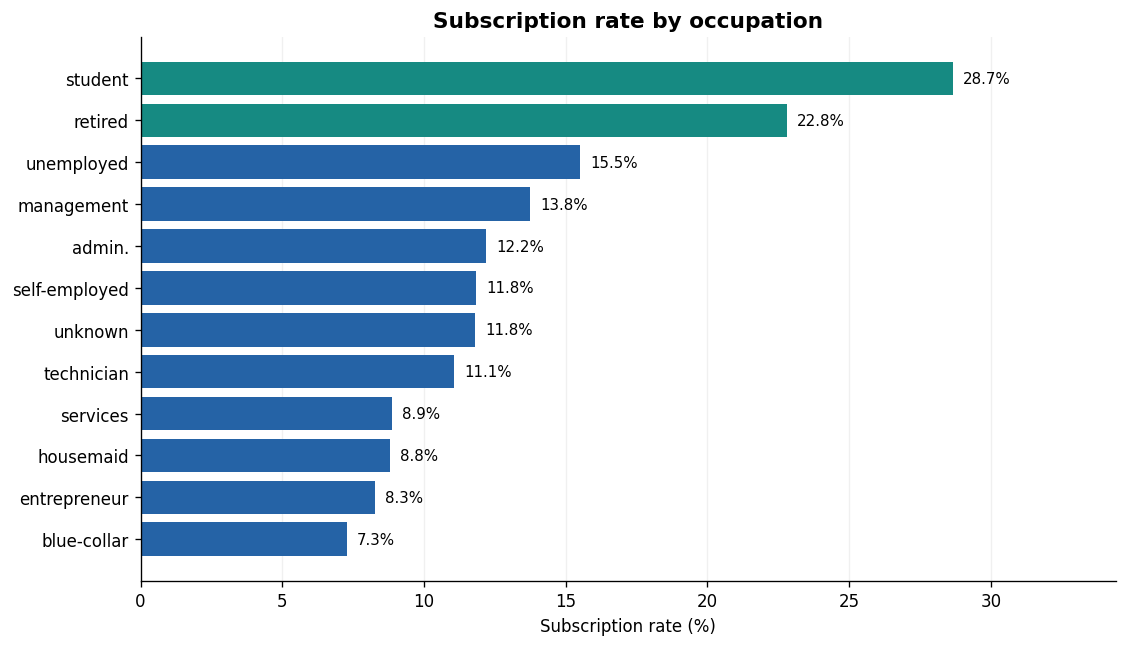

In [7]:
job_summary = pd.DataFrame({
    "customers": df.groupby("job")["y"].size(),
    "subscriptions": df.groupby("job")["y"].apply(lambda s: s.eq("yes").sum()),
})
job_summary["rate_pct"] = 100 * job_summary["subscriptions"] / job_summary["customers"]
job_summary = job_summary.sort_values("rate_pct")
display(job_summary.sort_values("rate_pct", ascending=False).round(2))
fig, ax = plt.subplots(figsize=(9.5, 5.5))
bars = ax.barh(job_summary.index, job_summary["rate_pct"], color=[TEAL if x in ("student", "retired") else BLUE for x in job_summary.index])
for bar, value in zip(bars, job_summary["rate_pct"]):
    ax.text(value + 0.35, bar.get_y() + bar.get_height()/2, f"{value:.1f}%", va="center", fontsize=9)
ax.set(title="Subscription rate by occupation", xlabel="Subscription rate (%)", xlim=(0, job_summary["rate_pct"].max()*1.2))
ax.grid(axis="x")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 6 · Age and subscription

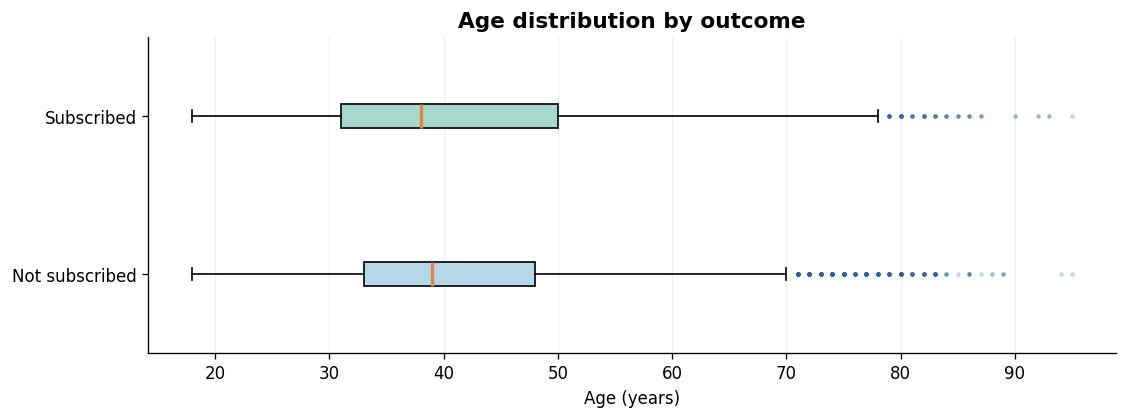

y
no     39.0
yes    38.0
Name: Median age, dtype: float64

In [8]:
age_groups = [df.loc[df["y"].eq(label), "age"] for label in ["no", "yes"]]
fig, ax = plt.subplots(figsize=(9.5, 3.6))
plot = ax.boxplot(age_groups, vert=False, patch_artist=True,
                  flierprops={"marker": ".", "markersize": 3, "alpha": 0.3, "markeredgecolor": BLUE},
                  medianprops={"color": ORANGE, "linewidth": 2})
for box, col in zip(plot["boxes"], [PALE, "#A7D8CC"]):
    box.set_facecolor(col)
ax.set(yticks=[1, 2], yticklabels=["Not subscribed", "Subscribed"],
       title="Age distribution by outcome", xlabel="Age (years)")
ax.grid(axis="x")
plt.tight_layout()
plt.show()
display(df.groupby("y")["age"].median().rename("Median age"))

,customers,subscriptions,rate_pct
age_group,,,
Young (≤18),12,7,58.33
Young adults (19–30),7018,1138,16.22
Adults (31–45),23733,2345,9.88
Middle-aged (46–60),13260,1297,9.78
Seniors (61–75),927,385,41.53
Elderly (76+),261,117,44.83


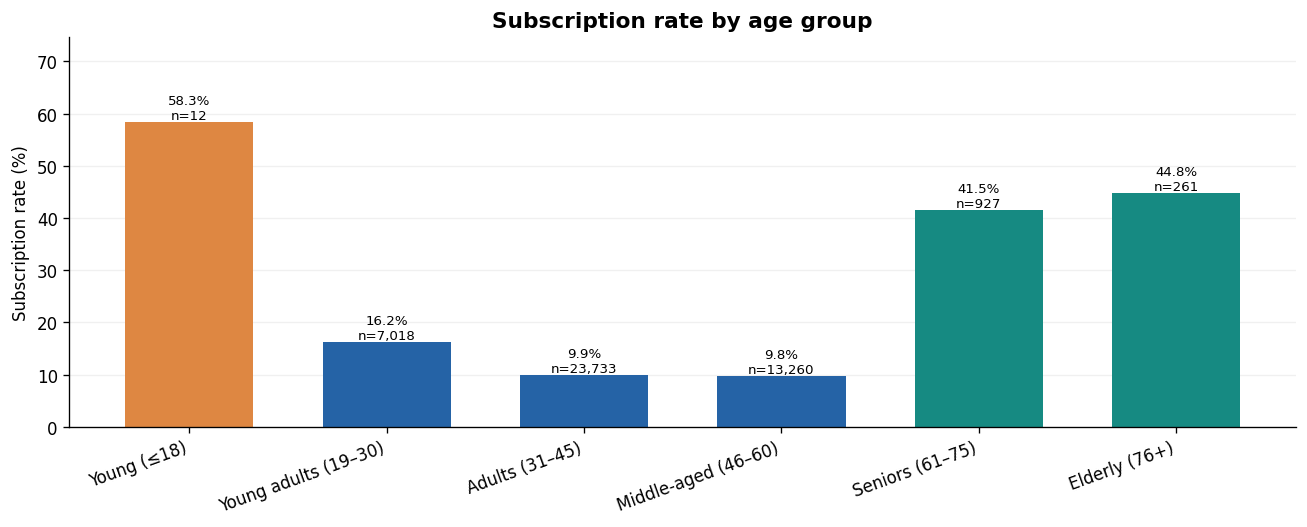

In [9]:
age_edges = [0, 18, 30, 45, 60, 75, 100]
age_labels = ["Young (≤18)", "Young adults (19–30)", "Adults (31–45)",
              "Middle-aged (46–60)", "Seniors (61–75)", "Elderly (76+)"]
df["age_group"] = pd.cut(df["age"], bins=age_edges, labels=age_labels)
age_summary = df.groupby("age_group", observed=True)["y"].agg(
    customers="size", subscriptions=lambda s: s.eq("yes").sum()
)
age_summary["rate_pct"] = 100 * age_summary["subscriptions"] / age_summary["customers"]
display(age_summary.round(2))
fig, ax = plt.subplots(figsize=(11, 4.5))
bars = ax.bar(range(len(age_summary)), age_summary["rate_pct"], color=[ORANGE] + [BLUE]*3 + [TEAL]*2, width=0.65)
ax.set_xticks(range(len(age_summary)), age_summary.index, rotation=20, ha="right")
for bar, row in zip(bars, age_summary.itertuples()):
    ax.annotate(f"{row.rate_pct:.1f}%\nn={row.customers:,}",
                (bar.get_x() + bar.get_width()/2, bar.get_height()), ha="center", va="bottom", fontsize=8)
ax.set(title="Subscription rate by age group", ylabel="Subscription rate (%)", ylim=(0, age_summary["rate_pct"].max()*1.28))
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Caution:** The youngest group contains very few customers, so its observed rate should not be treated as a robust targeting recommendation.

## 7 · Campaign contacts and conversion

,customers,subscriptions,rate_pct
campaign_group,,,
Low (1–2),30049,3962,13.19
Moderate (3–5),10807,1074,9.94
High (6–10),3159,206,6.52
Very high (11+),1196,47,3.93


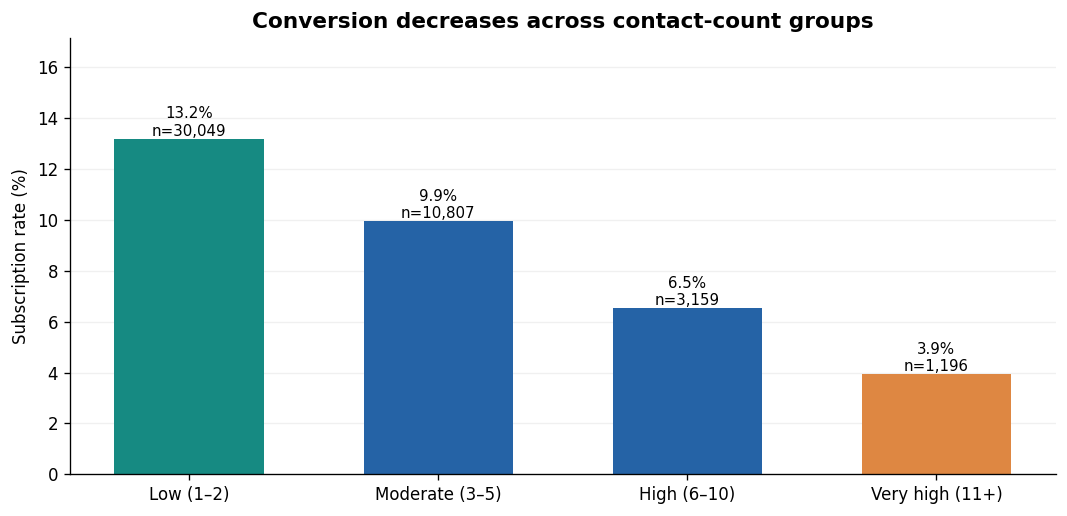

In [10]:
df["campaign_group"] = pd.cut(df["campaign"], bins=[0, 2, 5, 10, float("inf")],
                              labels=["Low (1–2)", "Moderate (3–5)", "High (6–10)", "Very high (11+)"])
campaign_summary = df.groupby("campaign_group", observed=True)["y"].agg(
    customers="size", subscriptions=lambda s: s.eq("yes").sum()
)
campaign_summary["rate_pct"] = 100 * campaign_summary["subscriptions"] / campaign_summary["customers"]
display(campaign_summary.round(2))
fig, ax = plt.subplots(figsize=(9, 4.4))
bars = ax.bar(campaign_summary.index, campaign_summary["rate_pct"], color=[TEAL, BLUE, BLUE, ORANGE], width=0.6)
for bar, row in zip(bars, campaign_summary.itertuples()):
    ax.annotate(f"{row.rate_pct:.1f}%\nn={row.customers:,}",
                (bar.get_x()+bar.get_width()/2, bar.get_height()), ha="center", va="bottom", fontsize=9)
ax.set(title="Conversion decreases across contact-count groups", ylabel="Subscription rate (%)",
       ylim=(0, campaign_summary["rate_pct"].max()*1.3))
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Interpretation:** Repeated contact is associated with lower observed conversion, but the analysis cannot establish whether repeated calling *causes* lower interest.

## 8 · Call duration and leakage risk

y
no     164.0
yes    426.0
Name: Median duration (seconds), dtype: float64

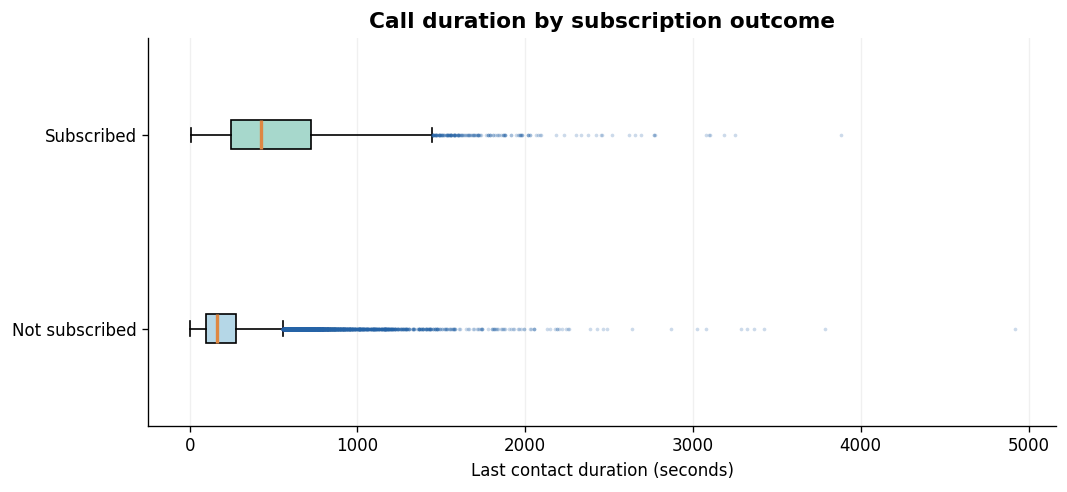

In [11]:
duration_groups = [df.loc[df["y"].eq(label), "duration"] for label in ["no", "yes"]]
display(df.groupby("y")["duration"].median().rename("Median duration (seconds)"))
fig, ax = plt.subplots(figsize=(9, 4.2))
plot = ax.boxplot(duration_groups, vert=False, patch_artist=True,
                  flierprops={"marker": ".", "markersize": 2.4, "alpha": 0.23, "markeredgecolor": BLUE},
                  medianprops={"color": ORANGE, "linewidth": 2})
for box, col in zip(plot["boxes"], [PALE, "#A7D8CC"]):
    box.set_facecolor(col)
ax.set(yticks=[1, 2], yticklabels=["Not subscribed", "Subscribed"],
       title="Call duration by subscription outcome", xlabel="Last contact duration (seconds)")
ax.grid(axis="x")
plt.tight_layout()
plt.show()

**Leakage note:** Final call duration is not known before a call. It is useful for historical EDA but would be unavailable to a model predicting subscription *before* calling a customer.

## 9 · Account balance and subscription

y
no     417.0
yes    733.0
Name: Median balance, dtype: float64

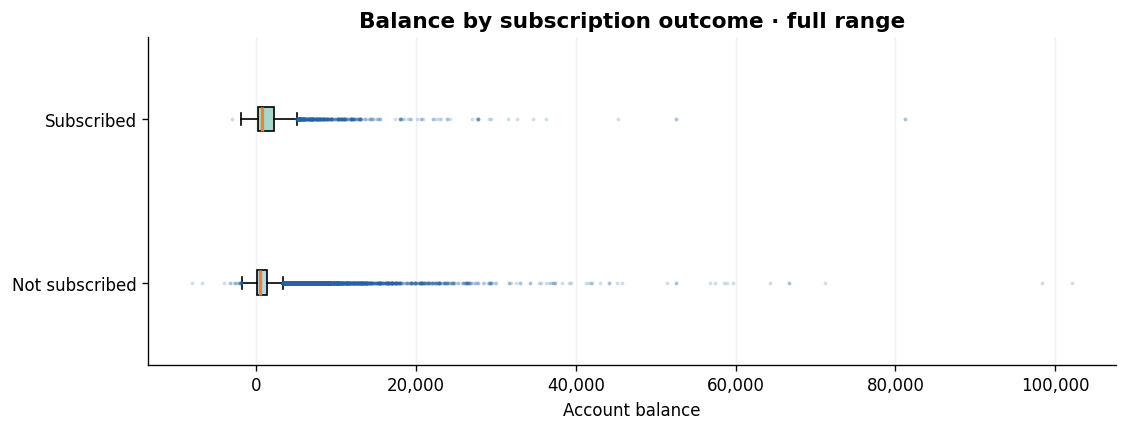

In [12]:
display(df.groupby("y")["balance"].median().rename("Median balance"))
fig, ax = plt.subplots(figsize=(9.5, 3.7))
plot = ax.boxplot([df.loc[df["y"].eq(v), "balance"] for v in ["no", "yes"]],
                  vert=False, patch_artist=True,
                  flierprops={"marker": ".", "markersize": 2.5, "alpha": 0.22, "markeredgecolor": BLUE},
                  medianprops={"color": ORANGE, "linewidth": 2})
for box, col in zip(plot["boxes"], [PALE, "#A7D8CC"]):
    box.set_facecolor(col)
ax.set(yticks=[1, 2], yticklabels=["Not subscribed", "Subscribed"],
       title="Balance by subscription outcome · full range", xlabel="Account balance")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}"))
ax.grid(axis="x")
plt.tight_layout()
plt.show()

,customers,subscriptions,min_balance,max_balance,rate_pct
balance_group,,,,,
Very low,9053,630,-8019,22,6.96
Low,9060,906,23,272,10.00
Medium,9017,1056,273,701,11.71
High,9039,1217,702,1859,13.46
Very high,9042,1480,1860,102127,16.37


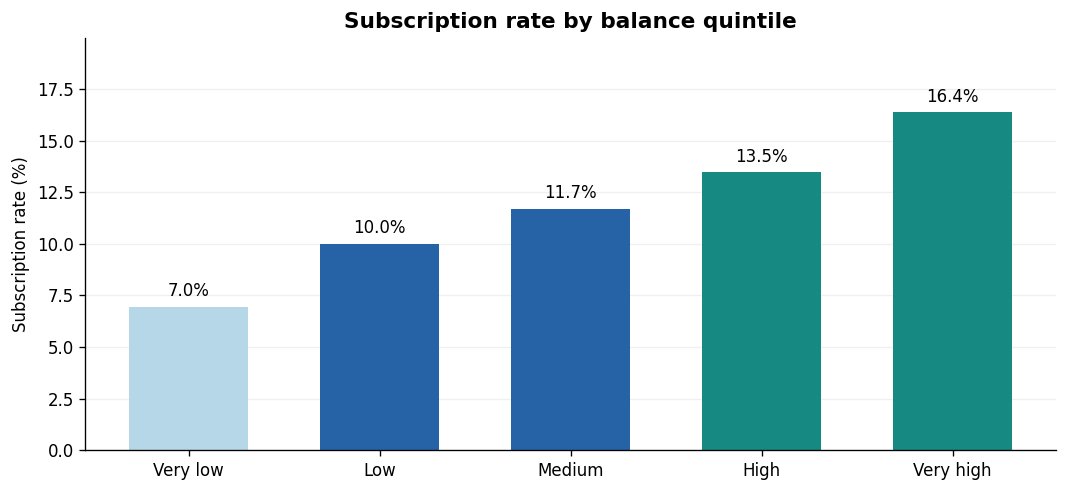

In [13]:
df["balance_group"] = pd.qcut(df["balance"], q=5,
    labels=["Very low", "Low", "Medium", "High", "Very high"])
balance_summary = df.groupby("balance_group", observed=True).agg(
    customers=("y", "size"),
    subscriptions=("y", lambda s: s.eq("yes").sum()),
    min_balance=("balance", "min"),
    max_balance=("balance", "max"),
)
balance_summary["rate_pct"] = 100 * balance_summary["subscriptions"] / balance_summary["customers"]
display(balance_summary.round(2))
fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.bar(balance_summary.index, balance_summary["rate_pct"],
              color=[PALE, BLUE, BLUE, TEAL, TEAL], width=0.62)
for bar, value in zip(bars, balance_summary["rate_pct"]):
    ax.annotate(f"{value:.1f}%", (bar.get_x()+bar.get_width()/2, value),
                ha="center", va="bottom", xytext=(0, 4), textcoords="offset points")
ax.set(title="Subscription rate by balance quintile", ylabel="Subscription rate (%)",
       ylim=(0, balance_summary["rate_pct"].max()*1.22))
ax.grid(axis="y")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 10 · Key findings and recommendations

| Area | Key finding | Implication / caveat |
|---|---|---|
| **Occupation** | Students (28.68%) and retired customers (22.79%) have high observed subscription rates; management generates the most subscriptions (1,301). | Evaluate both *rate* and *volume*. Differences are not necessarily caused by occupation. |
| **Age** | Seniors (41.53%) and elderly customers (44.83%) show elevated rates. The youngest group reaches 58.33%, but has only 12 records. | Treat small groups cautiously; verify patterns before targeting. |
| **Contacts** | Subscription rates drop from 13.19% (1–2 contacts) to 3.93% (11+). | Review follow-up strategy, but do not infer that reducing contacts would cause conversion to improve. |
| **Duration** | Median call duration is 426 seconds for subscribers versus 164 for non-subscribers. | Useful descriptive signal, but unavailable before a call: **prediction-time leakage risk**. |
| **Balance** | Subscription rate climbs from 6.96% in the lowest balance quintile to 16.37% in the highest. | Investigate balance-related targeting; conversion does not establish profitability. |

### Conclusion
The dataset contains **45,211** customer records and a relatively uncommon positive outcome (5,289 subscriptions). Occupation, age, contact frequency, call duration, and account balance are associated with subscription outcomes. High balances and long calls warrant careful interpretation; `unknown` and sentinel values should not be blindly deleted. Any change in marketing strategy needs further validation, ideally with experiments and profitability data.

### Limitations
- This is **observational EDA**, not causal inference.
- Campaign contact counts and durations are recorded during the campaign, so feature availability depends on prediction timing.
- Small subgroups have unstable percentage estimates.
- No cost or revenue data is available to establish which segments are most profitable.